# Silent Routing — Interactive Walkthrough

Compact, paper-aligned walkthrough of the Python two-block Transformer code in `handcoded/` for:

> **Silent Routing: How Step Supervision Trains Transformers Where Outcome Supervision Stalls** (ICML 2026)

This notebook demonstrates three core pieces from the paper:
1. **Shared Expressivity (Proposition 1 / Appendix B):** Construct both exact executors ($\theta^\star_{\mathrm{step}}$ and $\theta^\star_{\mathrm{out}}$) inside one two-block architecture and verify $100\%$ exact decoding.
2. **Exponential Outcome Plateau (Theorem 1 / Table 5):** Measure exact `float64` population GD exit times under step vs. outcome supervision as horizon $n$ grows.
3. **Paired Step vs. Outcome Training (Figure 1a):** Train both objectives from one shared random initialization $\theta_0$ and plot exact rollout accuracy.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import torch

ROOT = Path.cwd().parent if Path.cwd().name == "handcoded" else Path.cwd()
if str(ROOT / "handcoded") not in sys.path:
    sys.path.insert(0, str(ROOT / "handcoded"))

import lettertrace as lt
import regime_both as rb
from checks.executor_check import build_executors

print("PyTorch:", torch.__version__, "| Device:", "cuda" if torch.cuda.is_available() else "cpu")

PyTorch: 2.0.1+cu117 | Device: cuda


## 1. Shared Expressivity (Proposition 1)

Inside a single two-block normalization-free causal Transformer, both the exact step-by-step circuit $\theta^\star_{\mathrm{step}}$ and the exact direct-answer circuit $\theta^\star_{\mathrm{out}}$ achieve $100\%$ free-running accuracy.

In [2]:
cfg = lt.configure(task="count", alphabet=4, word_len=8, mod=2, train_size=2_000, test_size=500, seed=42)
_, _, test_examples = lt.make_corpus(cfg)

executors = lt.handcoded_params(cfg)
rebuilt = build_executors(cfg.task, cfg.word_len, cfg.alphabet, cfg.num_values)

for mode in ("process", "outcome"):
    exact_acc, answer_acc, _ = lt.free_run(executors[mode], test_examples, mode, cfg)
    tensors_equal = all(
        torch.equal(executors[mode][k].cpu().float(), rebuilt[mode][k].float())
        for k in executors[mode]
    )
    print(f"{mode:8s} executor -> exact={exact_acc:.3f}, answer={answer_acc:.3f}, appendix-B match={tensors_equal}")

corpus  train=2000  clean=2000/2000 (1.000)  test=500  (streams: train seed, corrupt seed+10000, test seed+20000)
process  executor -> exact=1.000, answer=1.000, appendix-B match=True
outcome  executor -> exact=1.000, answer=1.000, appendix-B match=True


## 2. Exact Float64 Population GD Exit Times (Theorem 1 / Table 5)

At small initialization scale $\varepsilon = 0.002$ with $V(0) = 0$ and match probability $p = 1/4$ ($\lambda = 1/2$), outcome exit time from $\mathcal B_\varepsilon$ grows as $\Omega(\lambda^{-n}) = \Omega(2^n)$ while step exit time stays $O(1)$.

In [3]:
regime_cfg = rb.RegimeConfig()
unit_params = rb.sample_unit_params(seed=0, cfg=regime_cfg)
unit_params["R"].zero_()
r_ball = rb.certified_ball_radius(unit_params, regime_cfg)

horizons = [4, 6, 8]
exit_times = {"step": [], "outcome": []}

for n in horizons:
    for mode in ("step", "outcome"):
        rec = rb.run_population_gd(
            word_len=n,
            sigma=0.002,
            mode=mode,
            unit_params=unit_params,
            stop_radius=r_ball,
            step_len=1e-4,
            cfg=regime_cfg,
        )
        exit_times[mode].append(rec["T"])
        print(f"n={n:2d}  {mode:8s}  T_exit(B_eps) = {rec['T']:.3e}  relu_flips = {rec['relu_flips']}")

n= 4  step      T_exit(B_eps) = 9.870e-02  relu_flips = {0.0017666782336900797: 0}
n= 4  outcome   T_exit(B_eps) = 2.883e+02  relu_flips = {0.0017666782336900797: 0}
n= 6  step      T_exit(B_eps) = 9.872e-02  relu_flips = {0.0017666782336900797: 0}
n= 6  outcome   T_exit(B_eps) = 1.440e+03  relu_flips = {0.0017666782336900797: 0}
n= 8  step      T_exit(B_eps) = 9.873e-02  relu_flips = {0.0017666782336900797: 0}
n= 8  outcome   T_exit(B_eps) = 6.980e+03  relu_flips = {0.0017666782336900797: 0}


## 3. Paired Step vs. Outcome Training from One Shared $\theta_0$ (Figure 1a)

Train both supervision formats from the exact same random initialization $\theta_0$ on modulo-2 counting ($n = 12$, 8,000 steps — `lettertrace.py`'s default config; step supervision sits on the flat $H(p)$ plateau before breaking out to $100\%$ exact rollout by 8k updates, while outcome stays at $50\%$ chance).

In [4]:
train_cfg = lt.configure(
    task="count",
    alphabet=4,
    word_len=12,
    mod=2,
    steps=8_000,
    eval_every=1_000,
    seed=42,
)
train_data, shown_data, test_data = lt.make_corpus(train_cfg)
theta_0 = lt.init_theta(train_cfg)

histories = {}
for mode in ("process", "outcome"):
    _, histories[mode] = lt.train_mode(mode, theta_0, train_data, shown_data, test_data, cfg=train_cfg)

corpus  train=20000  clean=20000/20000 (1.000)  test=1000  (streams: train seed, corrupt seed+10000, test seed+20000)


process:   0%|          | 0/4000 [00:00<?, ?it/s]

process  step   500  loss 0.4249  test exact 0.175  answer 0.493  step acc 0.572
process  step  1000  loss 0.3854  test exact 0.175  answer 0.493  step acc 0.572
process  step  1500  loss 0.3817  test exact 0.175  answer 0.493  step acc 0.572
process  step  2000  loss 0.3808  test exact 0.175  answer 0.493  step acc 0.572
process  step  2500  loss 0.3778  test exact 0.175  answer 0.493  step acc 0.572
process  step  3000  loss 0.3625  test exact 0.175  answer 0.493  step acc 0.572
process  step  3500  loss 0.3888  test exact 0.175  answer 0.493  step acc 0.572
process  step  4000  loss 0.3894  test exact 0.175  answer 0.493  step acc 0.572


outcome:   0%|          | 0/4000 [00:00<?, ?it/s]

outcome  step   500  loss 0.2329  test exact 0.495  answer 0.495
outcome  step  1000  loss 0.2311  test exact 0.495  answer 0.495
outcome  step  1500  loss 0.2310  test exact 0.505  answer 0.505
outcome  step  2000  loss 0.2324  test exact 0.505  answer 0.505
outcome  step  2500  loss 0.2316  test exact 0.505  answer 0.505
outcome  step  3000  loss 0.2299  test exact 0.505  answer 0.505
outcome  step  3500  loss 0.2312  test exact 0.505  answer 0.505
outcome  step  4000  loss 0.2319  test exact 0.505  answer 0.505


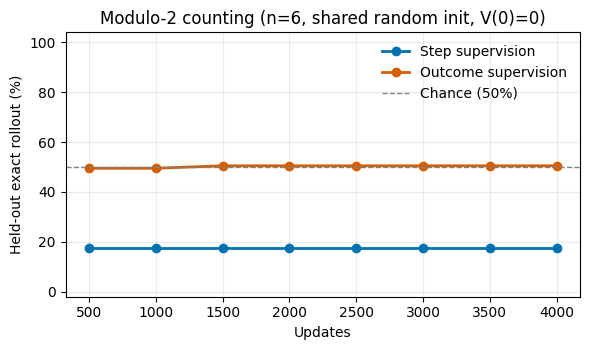

In [5]:
fig, ax = plt.subplots(figsize=(6, 3.6))
for mode, label, color in (("process", "Step supervision", "#0072B2"), ("outcome", "Outcome supervision", "#D55E00")):
    evals = [row for row in histories[mode] if "exact" in row]
    steps = [row["step"] for row in evals]
    exact = [100.0 * row["exact"] for row in evals]
    ax.plot(steps, exact, marker="o", lw=2, label=label, color=color)

ax.axhline(50.0, ls="--", color="gray", lw=1, label="Chance (50%)")
ax.set(xlabel="Updates", ylabel="Held-out exact rollout (%)", ylim=(-2, 104))
ax.set_title(f"Modulo-2 counting (n={train_cfg.word_len}, shared random init)")
ax.legend(frameon=False)
ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()